NAME: SIRIGIRI LEENA CHOWDARY

REG.NO : AP24110011180


   Principal Component  Explained Variance (%)  Cumulative Variance (%)
0                  PC1                   28.69                    28.69
1                  PC2                   17.08                    45.77
2                  PC3                   14.31                    60.07
3                  PC4                   11.01                    71.09
4                  PC5                    8.71                    79.80
5                  PC6                    6.05                    85.85
6                  PC7                    5.07                    90.92
7                  PC8                    3.81                    94.73
8                  PC9                    3.13                    97.86
9                 PC10                    1.61                    99.47
10                PC11                    0.53                   100.00


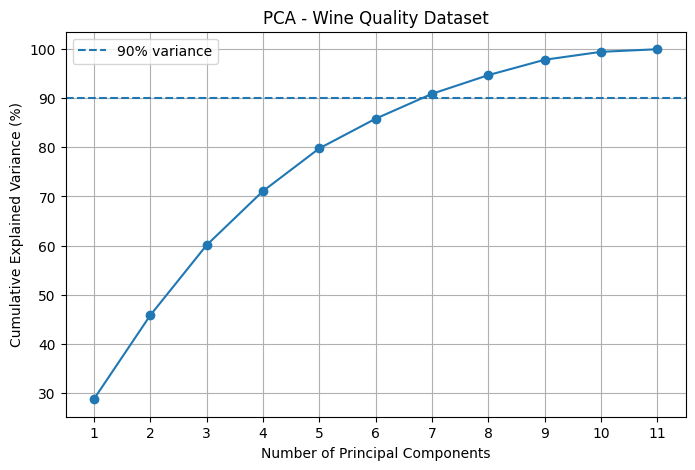


First five transformed records:
        PC1       PC2
0 -1.561545  0.444892
1 -0.760892  1.915058
2 -0.708085  0.914423
3  2.308166 -0.224448
4 -1.561545  0.444892

Variance retained by 2 components: 45.77 %


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv("/content/WineQT.csv")

# Select features and exclude target and ID
X = df.drop(columns=["quality", "Id"])

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = explained_variance.cumsum()                                   #AP24110011180

# Display results
results = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance (%)": explained_variance,
    "Cumulative Variance (%)": cumulative_variance
})

print(results.round(2))

# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=90, linestyle="--", label="90% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Wine Quality Dataset")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)
plt.legend()
plt.show()

# Reduce the dataset to 2 principal components
pca_2 = PCA(n_components=2)
X_2d = pca_2.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_2d, columns=["PC1", "PC2"])
print("\nFirst five transformed records:")
print(pca_df.head())
#AP24110010230
print("\nVariance retained by 2 components:",
      round(pca_2.explained_variance_ratio_.sum() * 100, 2), "%")
